# 4. From steady-state to dynamic model

## 4.1 Imports for Chapter 3

The following code block defines imports that will be used later in this notebook. There's no need to read through this code, simply run it and move to the next section

In [1]:
""" 
Imports needed for running the code
"""
# Ignore warnings during ODE solving
# Typically such warnings should be checked,
# but for the current exercise it is not important
import warnings
warnings.filterwarnings("ignore")

import os

from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import greenlight

## 4.2 A look back at the previous chapter's results

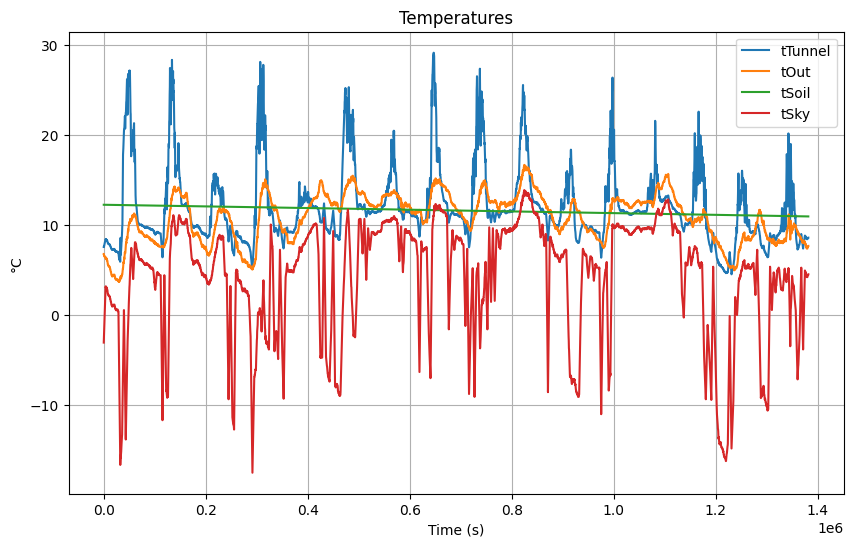

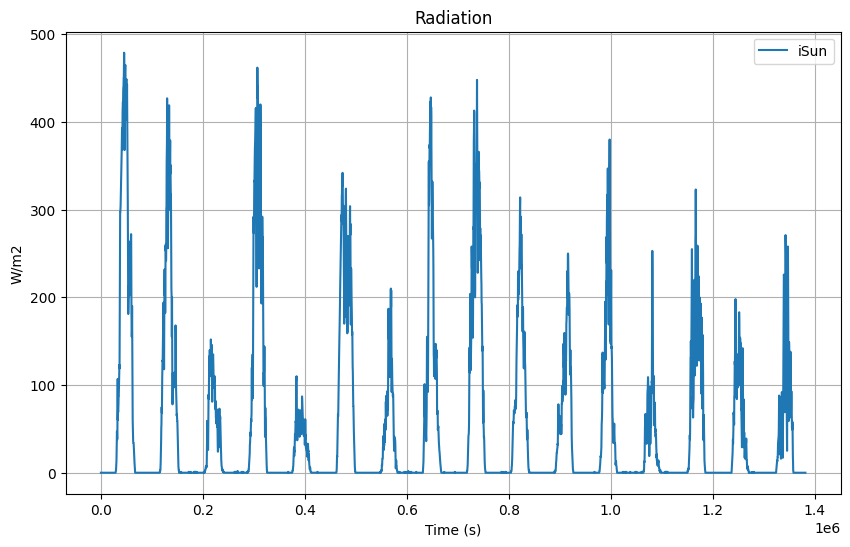

In [48]:
"""
Make graphs
"""

def display_output(output_df, chosen_vars, titles, ylabels, line_style):
    axes = []
    
    for vars_to_plot, title, ylabel in zip(chosen_vars, titles, ylabels):
        fig = plt.figure(figsize=(10, 6))
        ax = fig.add_subplot(111)
        
        for var in vars_to_plot:
            ax.plot(output_df["Time"], output_df[var], line_style, label=var)
        
        ax.set_xlabel("Time (s)")
        ax.set_ylabel(ylabel)
        ax.set_title(title)
        ax.legend()
        ax.grid(True)
        axes.append(ax)
        plt.show()

    return axes
        

# Load simulation result
output_2 = pd.read_csv(os.path.join("output", "output_2.csv"), header=[0,1,2], low_memory=False)

# Display
axes = display_output(output_2, [["tTunnel", "tOut",  "tSoil", "tSky"], ["iSun"]], ["Temperatures", "Radiation"], ["°C", "W/m2"], '-')

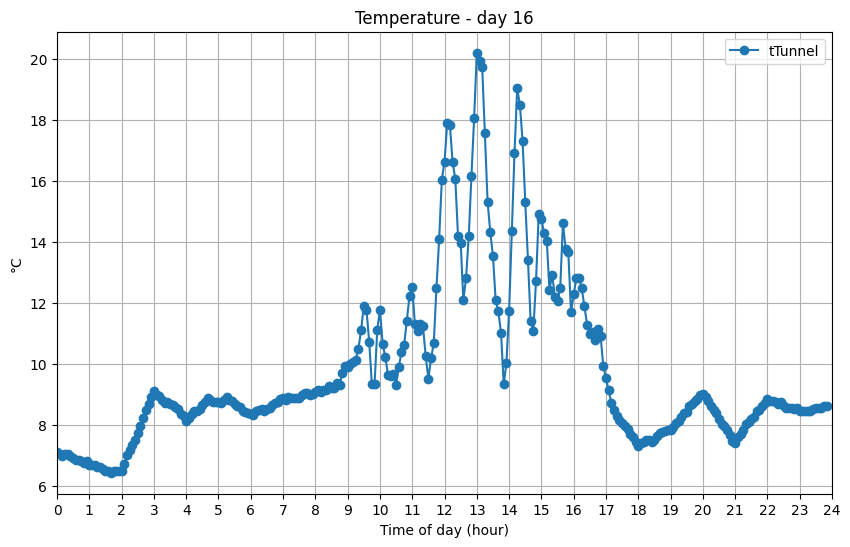

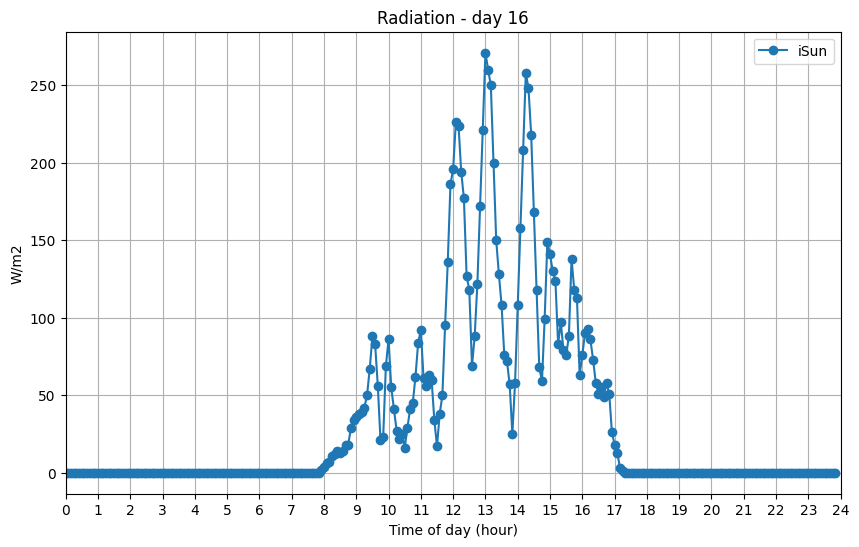

In [93]:
""" Zoom in """
def display_zoomed_output(output_df, day, chosen_vars, titles, ylabels, style, axes=None):  
    zoomed_output = output_df.copy()
    zoomed_output.columns = output_df.columns.get_level_values(0)
    zoomed_output = zoomed_output[zoomed_output["Time"] >= (day-1) * 24 * 60 * 60]
    zoomed_output = zoomed_output[zoomed_output["Time"] < day * 24 * 60 * 60]

    if axes is None:
        axes = [None] * len(titles)
        
    returned_axes = []
    for vars_to_plot, title, ylabel, ax in zip(chosen_vars, titles, ylabels, axes):
        if ax is None:
            fig = plt.figure(figsize=(10, 6))
            ax = fig.add_subplot(111)
        else:
            ax = ax
        
        for var in vars_to_plot:
            ax.plot((zoomed_output["Time"]/3600)%24, 
                    zoomed_output[var], 
                    style, 
                    label=var)
        
        ax.set_xlabel("Time of day (hour)")
        ax.set_xticks(np.arange(0, 25, step=1))
        ax.set_xlim([0, 24])
        ax.set_ylabel(ylabel)
        ax.set_title(f"{title} - day {day}")
        ax.legend()
        ax.grid(True)
        returned_axes.append(ax)

    return returned_axes

axes = display_zoomed_output(output_2, 
                      day=16, 
                      chosen_vars=[["tTunnel"], ["iSun"]], 
                      titles=["Temperature", "Radiation"], 
                      ylabels=["°C", "W/m2"], 
                      style='-o')

Exercise - what do you see here? Is this reasonable?

## Next step

Explain why this isn't good enough

Make a new model

In [113]:
# A guess at capacity:
# The air has a capacity of 1200 J/m3/K (Stanghellini textbook)
# Soil has a capacity of 1.73e6 J/m3/K (Vanthoor)
# Per m2 assume we consider 2.5 m of air and 0.1 m of soil, that gives:
# 1200x(2.5/2.6) + 1.73e6 (0.1/2.6) = 1153 + 66538 = 67691

import json

with open(os.path.join("output", "output_2_model_struct_log.json"), "r") as tunnel_def:
    dynamic_model = json.load(tunnel_def)


# Remove previous definitions of auxiliary states and states
del dynamic_model["auxiliary states"]
del dynamic_model["states"]

dynamic_model["tTunnel"] = {
        "description": "Temperature of the unventilated greenhouse",
        "unit": "°C",
        "reference": "Stanghellini et al. (2024), Eq. 3.9 (rearranged to isolate tTunnel)",
        "type": "state",
        "init": "8",
        "definition": "1/(67691)*(" \
        "tau * iSun " \
        "- fTunnelSky * epsCover * alphaR * (tTunnel - tSky) " \
        "- aCoverOverSoil * alphaCover * (tTunnel - tOut) " \
        "- fTunnelSoil * epsSoil * alphaR * (tTunnel - tSoil) " \
        "- alphaSoil * (tTunnel - tSoil)"
    ")"
    }



mdl_3 = greenlight.GreenLight(
    base_path=os.getcwd(), 
    input_prompt=[dynamic_model, os.path.join("input", "example_weather.csv")], 
    output_path=os.path.join("output", "output_3.csv")
)
mdl_3.run()



Loading model from input\example_weather.csv
Simulation started at time (ISO format): 2026-08-04T14:08:55.090942
Running: 100.00%

Simulation complete at time (ISO format): 2026-08-04T14:08:56.247438
Simulated 15.996527777777779 days
Elapsed time: 1.156496286392212 seconds
Output saved to file output\output_3.csv
Model structure log saved to output\output_3_model_struct_log.json
Simulation log saved to output\output_3_simulation_log.txt


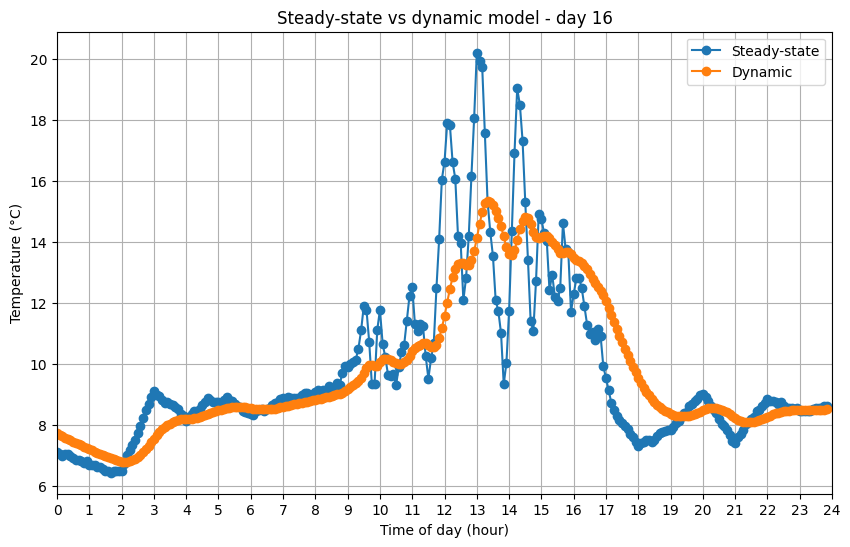

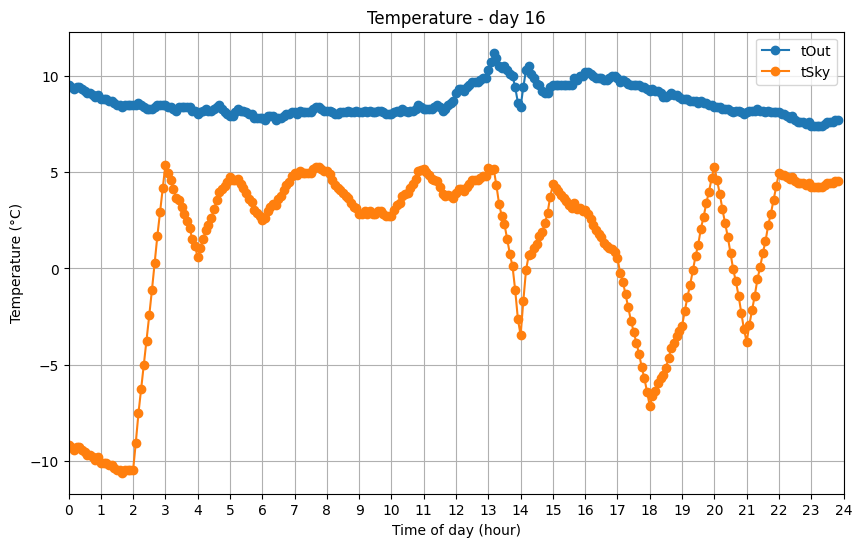

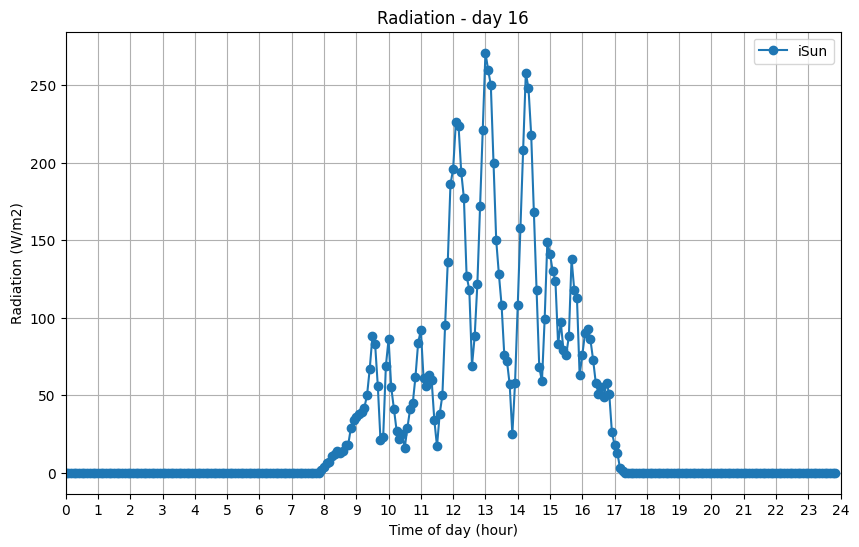

In [122]:
"""Load simulation result"""
output_3 = pd.read_csv(os.path.join("output", "output_3.csv"), header=[0,1,2], low_memory=False)

"""Make graphs"""
day = 16
axes = display_zoomed_output(output_2, 
                      day=day, 
                      chosen_vars=[["tTunnel"], ["tOut", "tSky"], ["iSun"]], 
                      titles=["Temperature", "Temperature", "Radiation"], 
                      ylabels=["Temperature (°C)", "Temperature (°C)", "Radiation (W/m2)"], 
                      style='-o')

axes = display_zoomed_output(output_3, 
                      day=day, 
                      chosen_vars=[["tTunnel"]], 
                      titles=["Temperature"], 
                      ylabels=["Temperature (°C)"], 
                      style='-o',
                      axes=axes)

axes[0].set_title(f"Steady-state vs dynamic model - day {day}")
axes[0].legend(["Steady-state", "Dynamic"]);